# Module 03 — Saturday: Beginner-Friendly ML Workshop

**Platform:** Jupyter Notebook or Google Colab. **Method:** understand → run → inspect → practice.

The dataset is synthetic and only for training. The same notebook can run on either platform. Run the setup once, then execute cells from top to bottom.

## Libraries for today's models and evaluation
The ML algorithms are modules inside **scikit-learn**, which we introduced Wednesday. **Matplotlib** is a separate library for drawing charts.

**Notebook setup (run only if a package is missing):**
```
%pip install scikit-learn matplotlib
```
**Terminal equivalent:** `python -m pip install -U scikit-learn matplotlib`.

- `sklearn.linear_model` — `LinearRegression` predicts a number, `LogisticRegression` predicts a class.
- `sklearn.tree` — `DecisionTreeClassifier` learns branches.
- `sklearn.ensemble` — `RandomForestClassifier` combines many trees.
- `sklearn.metrics` — accuracy, precision, recall, F1, MAE, MSE, and R².
- `matplotlib.pyplot` — charts and visual demonstrations.

In [150]:
import sklearn  # Load scikit-learn and check its version.
import matplotlib  # Load the plotting library.
from sklearn.linear_model import LinearRegression, LogisticRegression  # Two model classes.
from sklearn.metrics import accuracy_score, mean_absolute_error  # Two evaluation functions.
print("scikit-learn:", sklearn.__version__)  # Confirm ML tools are available.
print("Matplotlib:", matplotlib.__version__)  # Confirm chart tools are available.
print("Example accuracy:", accuracy_score([0, 1, 1], [0, 1, 0]))  # 2 of 3 correct.
print("Example MAE:", mean_absolute_error([70, 80], [75, 77]))  # Average absolute difference.

scikit-learn: 1.9.0
Matplotlib: 3.11.0
Example accuracy: 0.6666666666666666
Example MAE: 4.0


**Line-by-line code walkthrough**

- `import sklearn  # Load scikit-learn and check its version.` — Load scikit-learn and check its version.
- `import matplotlib  # Load the plotting library.` — Load the plotting library.
- `from sklearn.linear_model import LinearRegression, LogisticRegression  # Two model classes` — Two model classes.
- `from sklearn.metrics import accuracy_score, mean_absolute_error  # Two evaluation function` — Two evaluation functions.
- `print("scikit-learn:", sklearn.__version__)  # Confirm ML tools are available.` — Confirm ML tools are available.
- `print("Matplotlib:", matplotlib.__version__)  # Confirm chart tools are available.` — Confirm chart tools are available.
- `print("Example accuracy:", accuracy_score([0, 1, 1], [0, 1, 0]))  # 2 of 3 correct.` — 2 of 3 correct.
- `print("Example MAE:", mean_absolute_error([70, 80], [75, 77]))  # Average absolute differe` — Average absolute difference.

**2-minute student check:** Which module contains `RandomForestClassifier`? Which metric would you use to estimate how far a predicted exam score is from the actual score? Which library draws charts?

**Instructor key:** `sklearn.ensemble`; a regression-error metric such as MAE; Matplotlib. Accuracy is for classification, MAE is for numeric errors.

## Setup — common imports and dataset

If `student_learning.csv` is in your working directory, use it. Otherwise, generate a small synthetic practice dataset so that **the notebook still runs** on both Jupyter and Colab.

In [151]:
import pandas as pd  # Create and work with DataFrames.
import numpy as np  # Work with numerical data.
from pathlib import Path  # Work with file paths on any OS.
try:

    path = Path("student_learning.csv")  # Assign the resulting value to this variable for later use.
    df = pd.read_csv(path)  # Read the CSV file into a Pandas DataFrame.
    print("Dataset shape:", df.shape)  # Display the computed value or model result.
    print(df.head(3))  # Display the computed value or model result.
except FileNotFoundError:
    print("Student_learning file not found . please upload and try again")

Dataset shape: (280, 7)
   hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            7.5          54               0          5.6        video   
1            4.4          61               0          6.0        video   
2            8.2          63               1          5.2        group   

   final_score  passed  
0           48       0  
1           50       0  
2           73       1  


**Line-by-line code walkthrough**

- `import pandas as pd  # Create and work with DataFrames.` — Create and work with DataFrames.
- `import numpy as np  # Work with numerical data.` — Work with numerical data.
- `from pathlib import Path  # Work with file paths on any OS.` — Work with file paths on any OS.
- `path = Path("student_learning.csv")` — Assign the resulting value to this variable for later use.
- `if not path.exists():` — Run the indented steps only when the condition is true.
- `import gzip, base64` — Import the Python package used in the example.
- `encoded = """H4sIADk76GoC/2VZW05lOQz8Zy0RytNJVoMQ3B6QepoWlx5pdj9x2U58mL8mHBynXC4/+u3jz+f96` — Assign the resulting value to this variable for later use.
- `print("Created student_learning.csv automatically.")` — Display the computed value or model result.
- `df = pd.read_csv(path)` — Read the CSV file into a Pandas DataFrame.
- `print("Dataset shape:", df.shape)` — Display the computed value or model result.
- `print(df.head(3))` — Display the computed value or model result.

## Our safe classification setup

We predict `passed` using information available before the final result. We **exclude** `final_score` because using the final outcome to predict passing would leak the answer.

In [152]:
from sklearn.model_selection import train_test_split  # Import the functions or models needed for this step.
num = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]
X = df.drop(columns=["passed", "final_score"])  # Create a new table without the specified columns or rows.
y = df["passed"]  # Assign the resulting value to this variable for later use.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", X_train.shape, "Testing:", X_test.shape)  # Display the computed value or model result.

Training: (224, 5) Testing: (56, 5)


**Line-by-line code walkthrough**

- `from sklearn.model_selection import train_test_split` — Import the functions or models needed for this step.
- `num = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]` — Assign the resulting value to this variable for later use.
- `X = df.drop(columns=["passed", "final_score"])` — Create a new table without the specified columns or rows.
- `y = df["passed"]` — Assign the resulting value to this variable for later use.
- `X_train, X_test, y_train, y_test = train_test_split(` — Split features and labels into matching training and test groups.
- `X, y, test_size=0.20, random_state=42, stratify=y` — Assign the resulting value to this variable for later use.
- `print("Training:", X_train.shape, "Testing:", X_test.shape)` — Display the computed value or model result.

In [153]:
# Create a small numeric-only training/test set for first models.
Xn = df[["hours_studied", "attendance"]]  # Assign the resulting value to this variable for later use.
Xt, Xv, yt, yv = train_test_split(
    Xn, y, test_size=.20, random_state=42, stratify=y
)
features = ["hours_studied", "attendance"]  # Assign the resulting value to this variable for later use.
print("Ready for numerical demonstrations.")  # Display the computed value or model result.

Ready for numerical demonstrations.


**Line-by-line code walkthrough**

- `Xn = df[["hours_studied", "attendance"]]` — Assign the resulting value to this variable for later use.
- `Xt, Xv, yt, yv = train_test_split(` — Split features and labels into matching training and test groups.
- `Xn, y, test_size=.20, random_state=42, stratify=y` — Assign the resulting value to this variable for later use.
- `features = ["hours_studied", "attendance"]` — Assign the resulting value to this variable for later use.
- `print("Ready for numerical demonstrations.")` — Display the computed value or model result.

## Lesson 01 — A Quick Model Workflow Recap

**What it means:** A supervised model maps input features to a known target. The training portion teaches the pattern; held-out test records check whether the pattern generalizes.

**Why it is useful:** Every model comparison today uses the same split. Otherwise differences may be caused by easier or harder test examples rather than the algorithm.

**Real situation:** Compare a majority guess, a logistic model, a decision tree and a forest for predicting the passed column.

**Important terms:** **Feature matrix X:** Input columns; **Target y:** Known pass/fail outcomes; **Test metric:** Quality on unseen held-out rows

**Workflow:** Load dataset → Reuse the same split → Fit candidate models → Compare same test metric

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [154]:
import pandas as pd  # Import the Python package used in the example.
df = pd.read_csv("student_learning.csv")  # Read the CSV file into a Pandas DataFrame.
num = ["hours_studied", "attendance",
       "practice_tests", "sleep_hours"]
print(df[num + ["passed"]].head(3))  # Display the computed value or model result.

   hours_studied  attendance  practice_tests  sleep_hours  passed
0            7.5          54               0          5.6       0
1            4.4          61               0          6.0       0
2            8.2          63               1          5.2       1


**Line-by-line code walkthrough**

- `import pandas as pd` — Import the Python package used in the example.
- `df = pd.read_csv("student_learning.csv")` — Read the CSV file into a Pandas DataFrame.
- `num = ["hours_studied", "attendance",` — Assign the resulting value to this variable for later use.
- `print(df[num + ["passed"]].head(3))` — Display the computed value or model result.

**How to interpret the result:** The preview checks input ranges and the target before fitting models. The classification outcome is passed, not final_score.

**Common mistake:** Do not compare different test splits and then claim the highest score came from the better model.

### Student practice

Give one reason to keep the same test split when comparing models.

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

It makes the comparison fair: every candidate is judged on the same unseen records.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 02 — Linear Regression — Predict a Number

**What it means:** Linear regression predicts a numerical target using a weighted sum of inputs. For one input, the model is a line: predicted score = intercept + coefficient × study hours.

**Why it is useful:** The fitted line summarizes a relationship rather than memorizing each row. We use it as a simple, interpretable first regression model.

**Real situation:** Use `hours_studied` to estimate `final_score`. One hour of additional study changes the model prediction by the learned coefficient, holding other inputs fixed.

**Important terms:** **Coefficient:** Change in predicted output per unit of input; **Intercept:** Predicted value when input equals zero; **Residual:** Actual value minus predicted value

**Workflow:** Choose numeric target → Fit a line on training rows → Predict held-out scores → Compare with true scores

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [155]:
from sklearn.linear_model import LinearRegression  # Import the functions or models needed for this step.
Xr = df[["practice_tests","attendance"]]  # Assign the resulting value to this variable for later use.
yr = df["final_score"]  # Assign the resulting value to this variable for later use.
reg = LinearRegression()  # Assign the resulting value to this variable for later use.
reg.fit(Xr, yr)  # Small teaching demo
new = pd.DataFrame({"practice_tests": [10],"attendance":[20]})  # Assign the resulting value to this variable for later use.
print(reg.predict(new))  # Display the computed value or model result.

[49.87845921]


**Line-by-line code walkthrough**

- `from sklearn.linear_model import LinearRegression` — Import the functions or models needed for this step.
- `Xr = df[["hours_studied"]]` — Assign the resulting value to this variable for later use.
- `yr = df["final_score"]` — Assign the resulting value to this variable for later use.
- `reg = LinearRegression()` — Assign the resulting value to this variable for later use.
- `reg.fit(Xr, yr)  # Small teaching demo` — Small teaching demo
- `new = pd.DataFrame({"hours_studied": [5]})` — Assign the resulting value to this variable for later use.
- `print(reg.predict(new))` — Display the computed value or model result.

**How to interpret the result:** predict([[5]]) estimates a score for five study hours. A matching DataFrame preserves the same feature name used in training.

**Common mistake:** The line is not proof that studying causes exactly that many marks. Real outcomes depend on many factors.

### Student practice

Train a model using attendance instead of hours_studied. Predict the score for 80% attendance.

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

reg.fit(df[["attendance"]], yr); reg.predict(pd.DataFrame({"attendance":[80]})).

**Teaching note:** For fair assessment, use train/test split; full-data fit above only teaches the syntax.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [156]:
# Predict a numeric target with one numeric input.
from sklearn.linear_model import LinearRegression  # Import the functions or models needed for this step.
reg_att = LinearRegression()  # Assign the resulting value to this variable for later use.
reg_att.fit(df[["attendance"]], df["final_score"])  # Fit the estimator using the provided training examples.
new = pd.DataFrame({"attendance": [80]})  # Assign the resulting value to this variable for later use.
print("Predicted score:", reg_att.predict(new).round(1))  # Display the computed value or model result.

Predicted score: [59.7]


**Line-by-line code walkthrough**

- `from sklearn.linear_model import LinearRegression` — Import the functions or models needed for this step.
- `reg_att = LinearRegression()` — Assign the resulting value to this variable for later use.
- `reg_att.fit(df[["attendance"]], df["final_score"])` — Fit the estimator using the provided training examples.
- `new = pd.DataFrame({"attendance": [80]})` — Assign the resulting value to this variable for later use.
- `print("Predicted score:", reg_att.predict(new).round(1))` — Display the computed value or model result.

## Lesson 03 — Regression Errors: MAE, MSE and RMSE

**What it means:** Regression errors measure how far predicted numbers are from true values. MAE averages absolute errors. MSE squares errors. RMSE is the square root of MSE.

**Why it is useful:** MAE is easy to explain in the original units, while RMSE penalizes large misses more strongly. We choose metrics based on what kinds of errors matter.

**Real situation:** If a model predicts 70 instead of 80, its absolute error is 10 marks. A few large misses raise RMSE more than MAE.

**Important terms:** **MAE:** Average |actual - predicted|; **MSE:** Average squared error; squared units; **RMSE:** Square root of MSE; original units

**Workflow:** Predict held-out scores → Compute absolute differences → Average or square errors → Interpret in mark units

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [157]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,)
actual = [70, 80, 90]  # Assign the resulting value to this variable for later use.
pred = [72, 76, 93]  # Assign the resulting value to this variable for later use.
mae = mean_absolute_error(actual, pred)  # calculate mae.
mse = mean_squared_error(actual, pred)  # calculate mse.
rmse= np.sqrt(mse)
print(round(mae, 2), round(mse, 2),round(rmse, 2))  # Display the computed value or model result.

3.0 9.67 3.11


In [158]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,)
actual = [65, 83, 90, 79, 87]  # Assign the resulting value to this variable for later use.
pred = [72, 54, 66, 78, 97]  # Assign the resulting value to this variable for later use.
mae = mean_absolute_error(actual, pred)  # calculate mae.
mse = mean_squared_error(actual, pred)  # calculate mse.
rmse= np.sqrt(mse)
print(f"MAE:{round(mae, 2)}, MSE:{round(mse, 2)}, RMSE: {round(rmse, 2)}")  # Display the computed value or model result.

MAE:14.2, MSE:313.4, RMSE: 17.7


**Line-by-line code walkthrough**

- `from sklearn.metrics import (` — Import the functions or models needed for this step.
- `actual = [70, 80, 90]` — Assign the resulting value to this variable for later use.
- `pred = [72, 76, 93]` — Assign the resulting value to this variable for later use.
- `mae = mean_absolute_error(actual, pred)` — Assign the resulting value to this variable for later use.
- `rmse = mean_squared_error(actual, pred)**0.5` — Assign the resulting value to this variable for later use.
- `print(round(mae, 2), round(rmse, 2))` — Display the computed value or model result.

**How to interpret the result:** Absolute errors are 2, 4 and 3, so MAE = 3 marks. RMSE is about 3.11 marks, slightly higher because it weighs larger errors more.

**Common mistake:** Never report MSE as if its unit were marks; the units are marks squared. RMSE returns to marks.

### Student practice

For actual [50, 60] and predicted [55, 70], calculate MAE by hand.

Write your answer in a new code cell. Explain the result in one sentence.

In [159]:
from sklearn.metrics import(
    mean_absolute_error, mean_squared_error
)
acutal = [50, 60]
predic = [55, 70]
mae = mean_absolute_error(acutal, predic)
mse = mean_squared_error(acutal, predic)
print(mae)
print(mse)

7.5
62.5


### Instructor solution and explanation

Errors are 5 and 10 marks; MAE = (5 + 10)/2 = 7.5 marks.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [160]:
# MAE is the mean of the absolute errors.
from sklearn.metrics import mean_absolute_error  # Import the functions or models needed for this step.
actual = [50, 60]  # Assign the resulting value to this variable for later use.
predicted = [55, 70]  # Assign the resulting value to this variable for later use.
print("MAE:", mean_absolute_error(actual, predicted))  # Display the computed value or model result.

MAE: 7.5


**Line-by-line code walkthrough**

- `from sklearn.metrics import mean_absolute_error` — Import the functions or models needed for this step.
- `actual = [50, 60]` — Assign the resulting value to this variable for later use.
- `predicted = [55, 70]` — Assign the resulting value to this variable for later use.
- `print("MAE:", mean_absolute_error(actual, predicted))` — Display the computed value or model result.

## Lesson 04 — R² and the Mean Baseline

**What it means:** R² compares the model against a baseline that predicts the average training outcome. R² = 1 is perfect; R² = 0 matches the mean baseline; negative means worse.

**Why it is useful:** A model can have a low average error yet still be weak if a simple baseline does just as well. Compare both error and R² on held-out rows.

**Real situation:** Predicting nearly identical marks for every student might look plausible but may not capture meaningful variation in the true scores.

**Important terms:** **R² = 1:** Perfect on the evaluated data; **R² = 0:** Similar to predicting a constant mean; **R² < 0:** Worse than the evaluated mean baseline

**Workflow:** Split data fairly → Predict held-out scores → Compute R² → Compare against mean predictor

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [161]:
from sklearn.metrics import r2_score  # Import the functions or models needed for this step.
actual = [50, 70, 90, 60]  # Assign the resulting value to this variable for later use.
pred = [52, 66, 88, 62]  # Assign the resulting value to this variable for later use.
print("R2:", round(r2_score(actual, pred), 3))  # Display the computed value or model result.
print("Perfect:", r2_score(actual, actual))  # Display the computed value or model result.

R2: 0.968
Perfect: 1.0


In [162]:
# lets check the r2 of our recently acutal and predic values
a = [50, 70, 90, 60] 
p = [49, 66, 85, 62] 
print(f"r2: {r2_score(a, p)}")

r2: 0.9474285714285714


TypeError: only 0-dimensional arrays can be converted to Python scalars

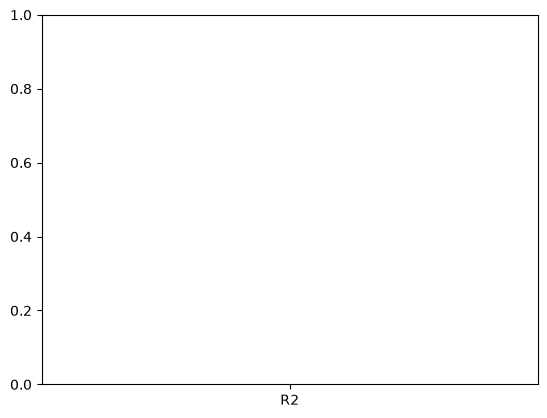

In [163]:
# lets show now in visualization
import matplotlib.pyplot as plt

metrices = ["R2","Prefect"]
values = [acutal, predic]

plt.bar(metrices, values)
plt.show()

**Line-by-line code walkthrough**

- `from sklearn.metrics import r2_score` — Import the functions or models needed for this step.
- `actual = [50, 70, 90, 60]` — Assign the resulting value to this variable for later use.
- `pred = [52, 66, 88, 62]` — Assign the resulting value to this variable for later use.
- `print("R2:", round(r2_score(actual, pred), 3))` — Display the computed value or model result.
- `print("Perfect:", r2_score(actual, actual))` — Display the computed value or model result.

**How to interpret the result:** The first score is close to 1 because errors are small compared with the variation in actual scores. Perfect self-predictions score exactly 1.

**Common mistake:** R² does not prove causation or reliability outside the data range. Negative values are possible and meaningful.

### Student practice

What does R² = -0.2 tell you about a model?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

It is worse than predicting the mean target on the evaluated records. Recheck inputs, split and model design.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 05 — Logistic Regression — Predict a Category

**What it means:** Despite its name, logistic regression is usually a classification algorithm. It calculates a score, transforms it to a probability and applies a threshold to choose a class.

**Why it is useful:** For a binary pass/fail target, it predicts the estimated probability of passing. Probabilities help us choose a different decision threshold when needed.

**Real situation:** A predicted probability of 0.75 means the model assigns a 75% chance to class 1 under its fitted assumptions, not that success is certain.

**Important terms:** **predict():** Returns 0 or 1 labels; **predict_proba():** Returns per-class probabilities; **Threshold:** Cutoff, often 0.50, for choosing class 1

**Workflow:** Prepare numeric features → Fit logistic classifier → Predict probabilities → Apply threshold to obtain labels

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
df.columns.to_list()

['hours_studied',
 'attendance',
 'practice_tests',
 'sleep_hours',
 'study_method',
 'final_score',
 'passed']

In [ ]:
from sklearn.linear_model import LogisticRegression  # Import the functions or models needed for this step.
from sklearn.model_selection import train_test_split  # Import the functions or models needed for this step.
Xn = df[["hours_studied", "attendance"]]  # Assign the resulting value to this variable for later use.
y = df["passed"]  # Assign the resulting value to this variable for later use.
Xt, Xv, yt, yv = train_test_split(
 Xn, y, test_size=.2, random_state=42, stratify=y)
logit = LogisticRegression(max_iter=200) # Fit the estimator using the provided training examples.
logit.fit(Xt, yt)
print(logit.predict_proba(Xv.head(3))[:,1].round(2))  # Display the computed value or model result.
#print(logit.predict(Xv))
print("Accuracy:", logit.score(Xv, yv)) #display accuracy of the model
print("Iterations used:", logit.n_iter_) #Display number of iterations taken by the model.

[0.86 0.27 0.45]
Accuracy: 0.75
Iterations used: [29]


In [ ]:
df['study_method'].unique()

<ArrowStringArray>
['video', 'group', 'self']
Length: 3, dtype: str

In [ ]:
print("=| Custom Test: use 3-X features |=")
Xni = df[["sleep_hours", "hours_studied", "attendance"]]
yi = df["passed"]
Xti, Xvi, yti, yvi = train_test_split(
    Xni, yi, test_size=0.2, random_state=42, stratify=y
)
log_reg = LogisticRegression(max_iter=200)
log_reg.fit(Xni, yi)
print(log_reg.predict_proba(Xvi.head(3))[:,1].round(2))
#print(log_reg.predict(Xvi))
print("Accuracy:", log_reg.score(Xvi, yvi)) #display accuracy of the model
print("Iterations used:", log_reg.n_iter_) #Display number of iterations taken by the model.

=| Custom Test: use 3-X features |=
[0.86 0.27 0.44]
Accuracy: 0.75
Iterations used: [40]


In [ ]:


# Create a new student with 6 study hours and 85% attendance.
new_student = pd.DataFrame({
    "hours_studied": [9],
    "attendance": [70]
})

# Predict whether the student will Pass or Fail.
prediction = log_reg.predict(new_student)

# Display the result.
print("Prediction:", prediction[0])

# Display the model's estimated probability of passing.
print("Pass probability:", log_reg.predict_proba(new_student)[0, 1])

**Line-by-line code walkthrough**

- `from sklearn.linear_model import LogisticRegression` — Import the functions or models needed for this step.
- `from sklearn.model_selection import train_test_split` — Import the functions or models needed for this step.
- `Xn = df[["hours_studied", "attendance"]]` — Assign the resulting value to this variable for later use.
- `y = df["passed"]` — Assign the resulting value to this variable for later use.
- `Xt, Xv, yt, yv = train_test_split(` — Split features and labels into matching training and test groups.
- `Xn, y, test_size=.2, random_state=42, stratify=y)` — Assign the resulting value to this variable for later use.
- `logit = LogisticRegression(max_iter=1000).fit(Xt, yt)` — Fit the estimator using the provided training examples.

**How to interpret the result:** The fitted model can now predict test labels using logit.predict(Xv) or probabilities with logit.predict_proba(Xv)[:, 1].

**Common mistake:** Do not fit and evaluate on the exact same rows. max_iter allows more optimization steps; it does not guarantee a better model.

### Student practice

Use the trained classifier to display probabilities for the first three test rows.

Write your answer in a new code cell. Explain the result in one sentence.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Probabilities correspond to class 1 (passed).
prob = logit.predict_proba(Xv.head(3))[:, 1]  # Assign the resulting value to this variable for later use.
print("Probability of pass:", prob.round(2))  # Display the computed value or model result.

Probability of pass: [0.86 0.27 0.45]


**Line-by-line code walkthrough**

- `prob = logit.predict_proba(Xv.head(3))[:, 1]` — Assign the resulting value to this variable for later use.
- `print("Probability of pass:", prob.round(2))` — Display the computed value or model result.

## Lesson 06 — Confusion Matrix — Four Outcomes

**What it means:** A confusion matrix counts correct and incorrect classifications. For class 1 = passed, it separates true positives, true negatives, false positives and false negatives.

**Why it is useful:** A single accuracy number hides which students are missed. False negatives may matter more when the purpose is early support for at-risk learners.

**Real situation:** Actual fail predicted pass = false positive. Actual pass predicted fail = false negative when pass is class 1.

**Important terms:** **TP / TN:** Correct positive / negative decisions; **FP:** Predicted positive, actually negative; **FN:** Predicted negative, actually positive

**Workflow:** Predict test labels → Compare against true labels → Count four outcomes → Discuss cost of errors

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
from sklearn.metrics import confusion_matrix  # Import the functions or models needed for this step.
actual = [1, 1, 0, 0, 1, 0]  # Assign the resulting value to this variable for later use.
pred =   [1, 0, 0, 1, 1, 0]  # Assign the resulting value to this variable for later use.
cm = confusion_matrix(actual, pred)  # Assign the resulting value to this variable for later use.
print(cm)  # Rows actual; columns predicted
print("Accuracy:", accuracy_score(actual,pred))

[[2 1]
 [1 2]]
Accuracy: 0.6666666666666666


**Line-by-line code walkthrough**

- `from sklearn.metrics import confusion_matrix` — Import the functions or models needed for this step.
- `actual = [1, 1, 0, 0, 1, 0]` — Assign the resulting value to this variable for later use.
- `pred =   [1, 0, 0, 1, 1, 0]` — Assign the resulting value to this variable for later use.
- `cm = confusion_matrix(actual, pred)` — Assign the resulting value to this variable for later use.
- `print(cm)  # Rows actual; columns predicted` — Rows actual; columns predicted

**How to interpret the result:** The matrix is [[2, 1], [1, 2]]: TN=2, FP=1, FN=1, TP=2. Both types of mistakes appear even though most predictions are correct.

**Common mistake:** Always state which class is positive. The meaning of FP and FN changes if class 0 is treated as the positive event.

### Student practice

If the goal is to identify students at risk (fail = 0), which class should be the positive event?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Treat class 0 as the class of interest; pass labels=[1,0] to confusion_matrix or report recall for class 0.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 07 — Accuracy, Precision, Recall and F1

**What it means:** Accuracy is the share of correct predictions. Precision checks how many predicted positives are truly positive. Recall checks how many actual positives we find.

**Why it is useful:** F1 is the harmonic mean of precision and recall. It is useful when both false positives and false negatives matter, especially with class imbalance.

**Real situation:** A model predicting everyone as pass may have high accuracy in a school where almost everyone passes, but it completely misses students who fail.

**Important terms:** **Accuracy:** All correct / all predictions; **Precision:** TP / (TP + FP); **Recall:** TP / (TP + FN)

**Workflow:** Pick the positive class → Count TP, FP and FN → Calculate metrics → Explain errors in context

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
from sklearn.metrics import (
 accuracy_score, precision_score, recall_score, f1_score)
a = [1, 0, 1, 0, 1, 0]  # Assign the resulting value to this variable for later use.
p = [1, 1, 1, 1, 1, 1]  # Assign the resulting value to this variable for later use.
print("Accuracy:", accuracy_score(a, p))  # Display the computed value or model result.
print("Precision:", precision_score(a, p))  # Display the computed value or model result.
print("Recall:", recall_score(a, p))  # Display the computed value or model result.
print("------------")
ai = [6, 7, 3]
pi = [5, 7, 3]
print("Accuracy:", accuracy_score(ai, pi))
# print("Precision:", precision_score(ai, pi))
# print("Recall:", recall_score(ai, pi))


Accuracy: 0.5
Precision: 0.5
Recall: 1.0
------------
Accuracy: 0.6666666666666666


ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].

**Line-by-line code walkthrough**

- `from sklearn.metrics import (` — Import the functions or models needed for this step.
- `a = [1, 1, 0, 0, 1, 0]` — Assign the resulting value to this variable for later use.
- `p = [1, 0, 0, 1, 1, 0]` — Assign the resulting value to this variable for later use.
- `print("Accuracy:", accuracy_score(a, p))` — Display the computed value or model result.
- `print("Precision:", precision_score(a, p))` — Display the computed value or model result.
- `print("Recall:", recall_score(a, p))` — Display the computed value or model result.

**How to interpret the result:** Here accuracy is 4/6, precision is 2/3 and recall is 2/3 for the positive class 1. F1 is also 2/3.

**Common mistake:** Accuracy alone is unsafe when one class is much more frequent. Always inspect target balance and a confusion matrix.

### Student practice

You care most about finding students likely to fail. Which metric should you emphasize?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Recall for the fail class helps measure how many truly at-risk students the model identifies.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 08 — Class Imbalance and Thresholds

**What it means:** Class imbalance means one outcome is much more common than another. Predicting only the majority class can look strong under accuracy while failing at the rare class.

**Why it is useful:** A threshold trades precision against recall. Lowering the cutoff usually predicts more positives, increasing recall but possibly increasing false alarms.

**Real situation:** If 95 of 100 customers do not churn, always predicting no churn gives 95% accuracy but 0% recall for churn.

**Important terms:** **Majority baseline:** Always predicts the most frequent label; **Class weight:** Give extra weight to less frequent class; **Decision threshold:** Probability cutoff for a positive prediction

**Workflow:** Count each class → Measure majority baseline → Inspect recall and precision → Adjust threshold thoughtfully

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
import numpy as np  # Import the Python package used in the example.
probs = np.array([.2, .4, .55, .8])  # Assign the resulting value to this variable for later use.
pred_50 = (probs >= .50).astype(int)  # Assign the resulting value to this variable for later use.
pred_30 = (probs >= .30).astype(int)  # Assign the resulting value to this variable for later use.
print("0.50:", pred_50)  # Display the computed value or model result.
print("0.30:", pred_30)  # Display the computed value or model result.

0.50: [0 0 1 1]
0.30: [0 1 1 1]


**Line-by-line code walkthrough**

- `import numpy as np` — Import the Python package used in the example.
- `probs = np.array([.2, .4, .55, .8])` — Assign the resulting value to this variable for later use.
- `pred_50 = (probs >= .50).astype(int)` — Assign the resulting value to this variable for later use.
- `pred_30 = (probs >= .30).astype(int)` — Assign the resulting value to this variable for later use.
- `print("0.50:", pred_50)` — Display the computed value or model result.
- `print("0.30:", pred_30)` — Display the computed value or model result.

**How to interpret the result:** At threshold 0.30, more records receive class 1 than at 0.50. Whether that improves your real goal depends on their true labels.

**Common mistake:** Do not choose the cutoff by repeatedly checking test results. Tune on validation data and reserve test data for final evaluation.

### Student practice

If you reduce threshold from 0.50 to 0.30, what is likely to happen to recall and false positives?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Recall often rises, but the number of false positives may also rise; check both metrics.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Compare more permissive and stricter thresholds.
import numpy as np  # Import the Python package used in the example.
p = np.array([0.1, 0.35, 0.55, 0.9])  # Assign the resulting value to this variable for later use.
print("At 0.50:", (p >= 0.50).astype(int))  # Display the computed value or model result.
print("At 0.30:", (p >= 0.30).astype(int))  # Display the computed value or model result.

At 0.50: [0 0 1 1]
At 0.30: [0 1 1 1]


**Line-by-line code walkthrough**

- `import numpy as np` — Import the Python package used in the example.
- `p = np.array([0.1, 0.35, 0.55, 0.9])` — Assign the resulting value to this variable for later use.
- `print("At 0.50:", (p >= 0.50).astype(int))` — Display the computed value or model result.
- `print("At 0.30:", (p >= 0.30).astype(int))` — Display the computed value or model result.

## Lesson 09 — Decision Trees — A Chain of Questions

**What it means:** A decision tree repeatedly asks questions such as “attendance <= 70?” and sends records down branches until a leaf produces a prediction.

**Why it is useful:** Shallow trees are easy to explain but may miss patterns. Deep trees can memorize training examples and perform poorly on new rows.

**Real situation:** A tree may first split on attendance, then study hours, then practice tests. Each branch describes a path toward a final pass/fail estimate.

**Important terms:** **Split:** A question used to divide records; **Leaf:** The end node containing a prediction; **max_depth:** Maximum number of levels of splits

**Workflow:** Start with training rows → Find helpful split → Repeat on smaller groups → Predict from final leaf

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
from sklearn.tree import DecisionTreeClassifier  # Import the functions or models needed for this step.
features = ["hours_studied", "attendance"]  # Assign the resulting value to this variable for later use.
treee = DecisionTreeClassifier(
    max_depth=5, random_state=42)  # Assign the resulting value to this variable for later use.
treee.fit(Xt[features], yt)  # Fit the estimator using the provided training examples.
print(treee.predict(Xv[features].head(3)))  # Display the computed value or model result.

[1 0 1]


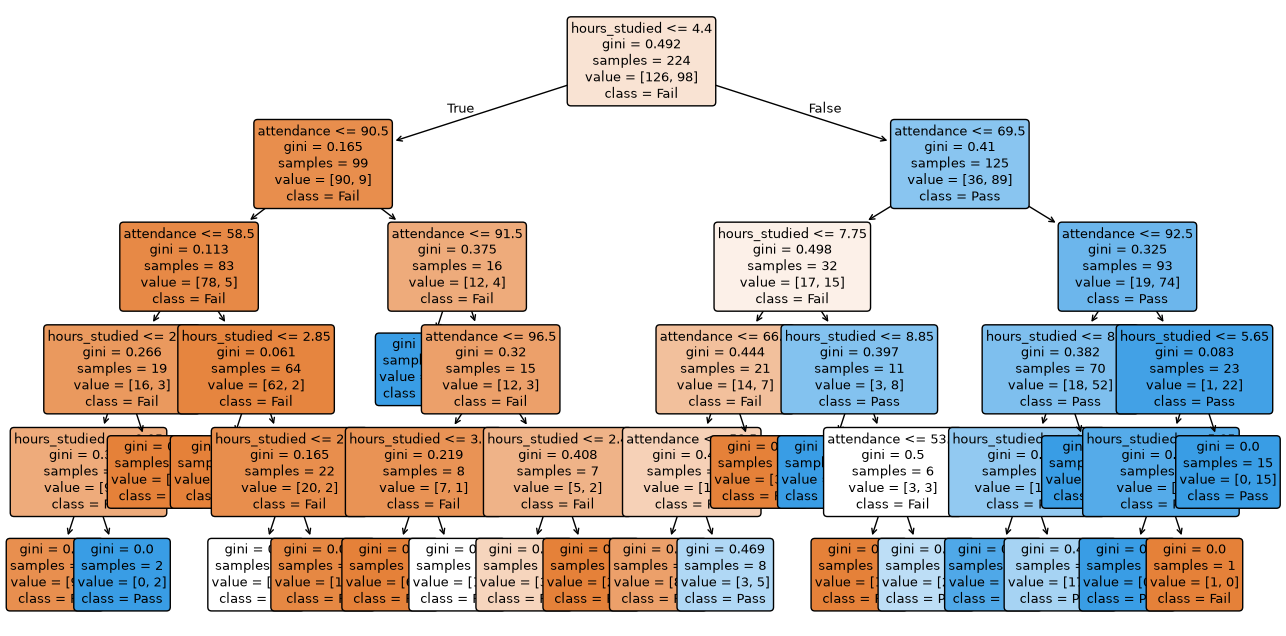

In [ ]:
# Import Matplotlib to create and display graphs or diagrams.
import matplotlib.pyplot as plt

# Import plot_tree from Scikit-learn to visualize a trained Decision Tree model.
from sklearn.tree import plot_tree

# Create a figure with a width of 16 inches and a height of 8 inches.
# A larger figure makes the Decision Tree easier to read.
plt.figure(figsize=(16, 8))

# Draw the Decision Tree that was previously trained using tree.fit().
plot_tree(
    tree,                           # The trained Decision Tree model.
    feature_names=features,         # Display feature names such as hours_studied and attendance.
    class_names=["Fail", "Pass"],   # Show class labels: 0 = Fail and 1 = Pass.
    filled=True,                    # Fill nodes with colors to represent the predicted classes.
    rounded=True,                   # Display tree nodes with rounded corners.
    fontsize=9                      # Set the text size inside the tree nodes.
)

# Display the complete Decision Tree diagram.
plt.show()

**What is this diagram showing?**

- Decision nodes: Questions such as hours_studied <= 4.5.
- Branches: Different paths depending on whether a condition is True or False.
- Gini: A measure of how mixed the classes are in a node.
- Samples: Number of training students reaching that node.
- Value: Number (or proportions) of training samples belonging to each class, depending on the Scikit-learn version and settings.
- Class: The class predicted at that node, such as Pass or Fail.

**How to interpret the result:** A shallow tree makes class predictions by following the same learned split questions for each new row.

**Common mistake:** max_depth=None may fit much more detail than the data can justify. Compare training and test scores, not only training score.

### Student practice

What changes when you decrease max_depth from 10 to 2?

Write your answer in a new code cell. Explain the result in one sentence.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
features = ["hours_studied", "attendance"]
treee = DecisionTreeClassifier(
    max_depth=10, random_state=42) 
treee.fit(Xt[features], yt)
print(treee.predict(Xv[features].head(3)))

[1 0 0]


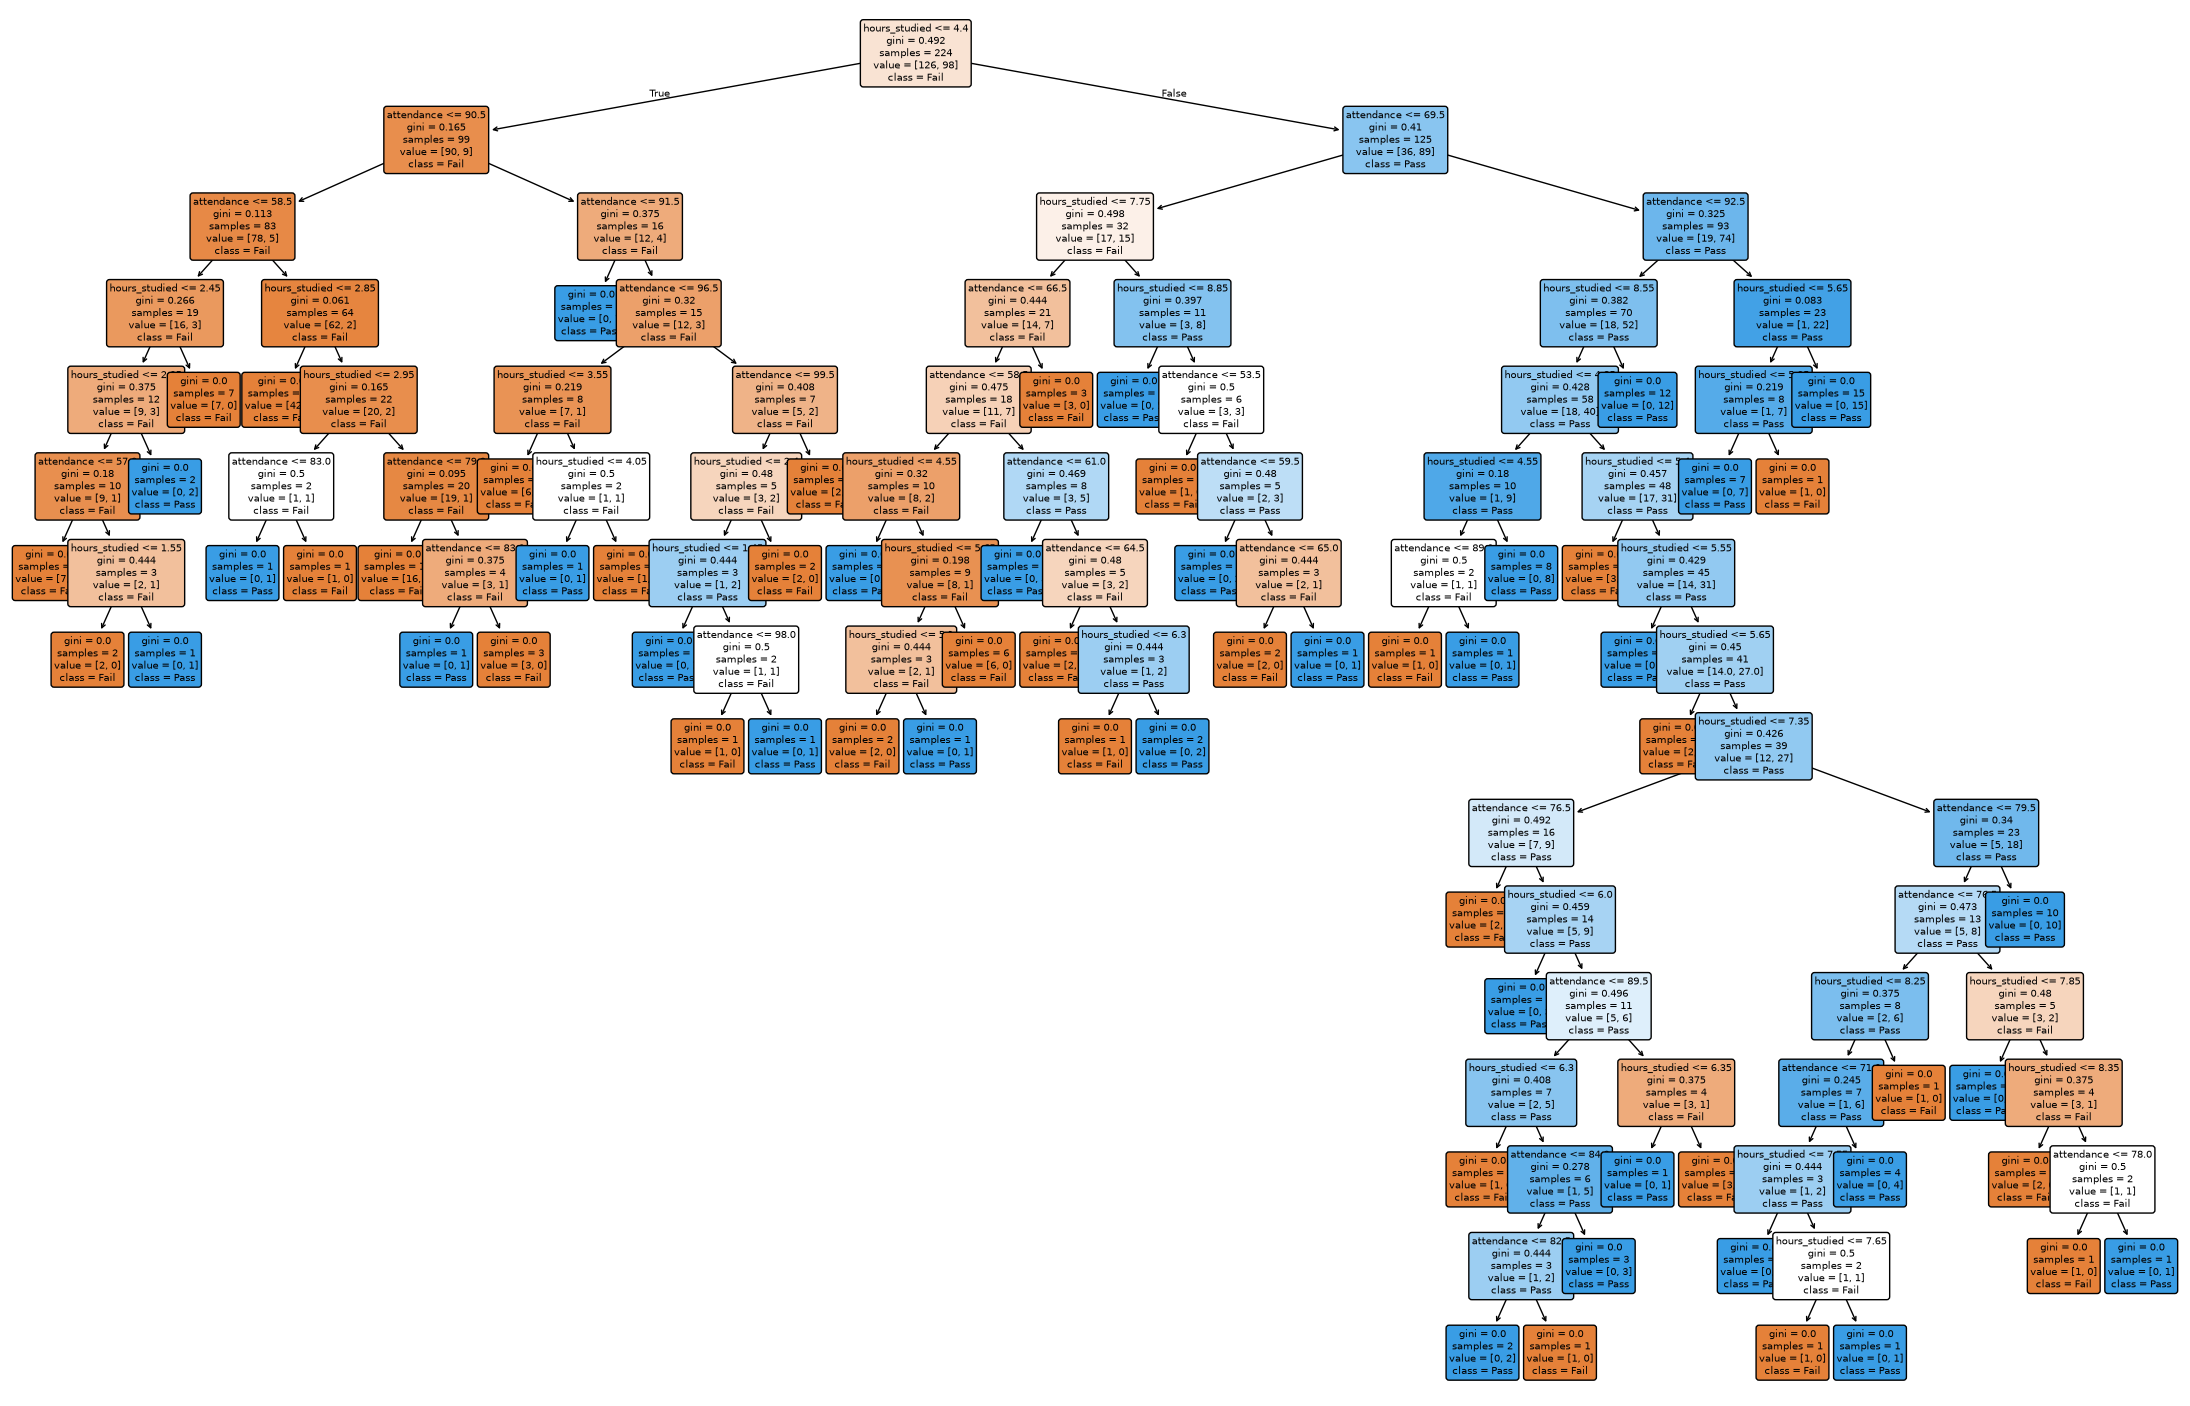

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# 1. Instantiate and train your model (don't name it plot_tree!)
model = DecisionTreeClassifier()
model.fit(Xt[features], yt)

# 2. Pass the MODEL variable inside the plot_tree function
plt.figure(figsize=(28, 18))
# plot_tree(model)  # <-- Pass 'model' here, NOT 'plot_tree'
plot_tree(
    model,                           # The trained Decision Tree model.
    feature_names=features,         # Display feature names such as hours_studied and attendance.
    class_names=["Fail", "Pass"],   # Show class labels: 0 = Fail and 1 = Pass.
    filled=True,                    # Fill nodes with colors to represent the predicted classes.
    rounded=True,                   # Display tree nodes with rounded corners.
    fontsize=7                      # Set the text size inside the tree nodes.
)
plt.show()

### Instructor solution and explanation

The tree becomes simpler, usually reducing overfitting but possibly increasing underfitting.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 10 — Random Forest — Many Trees Vote

**What it means:** A random forest trains many decision trees on different sampled rows and subsets of features. Their votes are combined for classification.

**Why it is useful:** A single tree can be unstable. Averaging many trees usually reduces sensitivity to small data changes, though the result is harder to explain fully.

**Real situation:** Different trees may disagree on a student; the forest chooses the majority predicted class across them.

**Important terms:** **n_estimators:** How many trees are trained; **max_depth:** Limits how complex each tree becomes; **random_state:** Makes random choices reproducible

**Workflow:** Sample training records → Grow many varied trees → Collect predictions → Take majority vote

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# Import Random Forest classification algorithm.
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest model containing 80 Decision Trees.
forest = RandomForestClassifier(
    n_estimators=80,    # Number of Decision Trees in the forest.
    max_depth=5,       # Maximum depth allowed for each tree.
    random_state=42    # Make training results reproducible.
)

# Train the forest using study hours, attendance, and actual Pass/Fail results.
forest.fit(Xt[features], yt)

# Predict Pass/Fail for the held-out students.
predictions = forest.predict(Xv[features])

# Display predictions for the first 5 students.
print("Predictions:", predictions[:5])

# Calculate classification accuracy on held-out data.
accuracy = forest.score(Xv[features], yv)

# Display accuracy rounded to 3 decimal places.
print("Accuracy:", round(accuracy, 3))

Predictions: [1 0 1 1 0]
Accuracy: 0.696


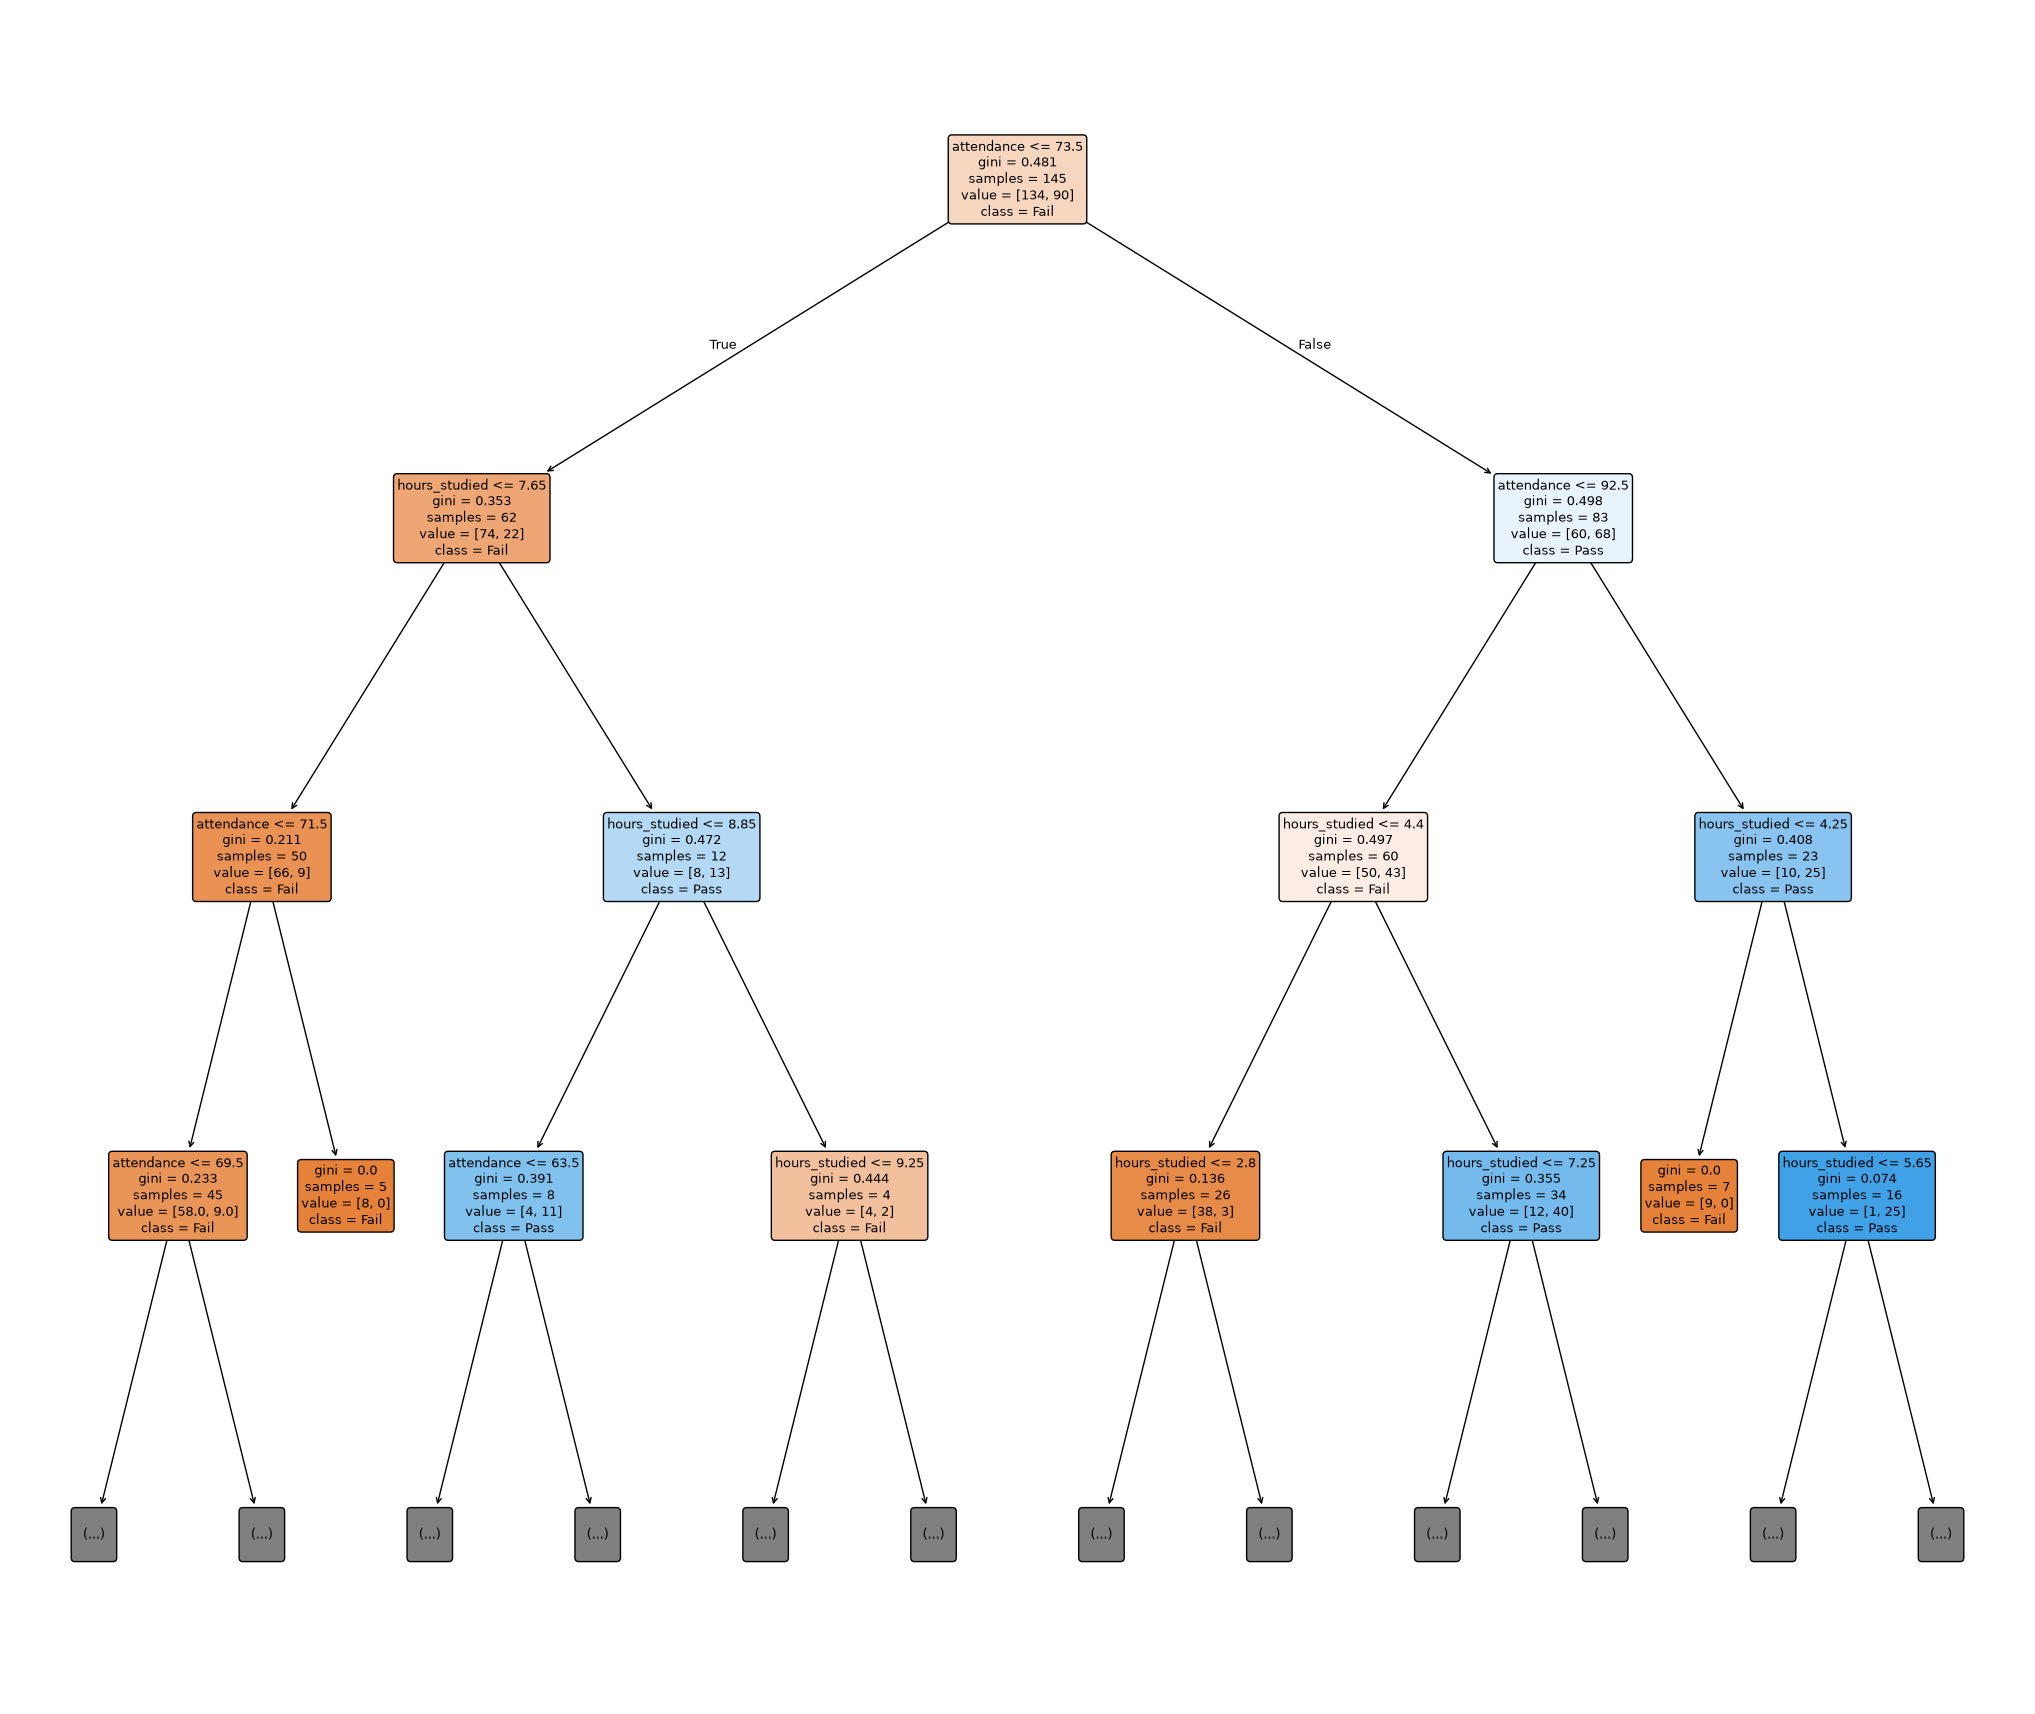

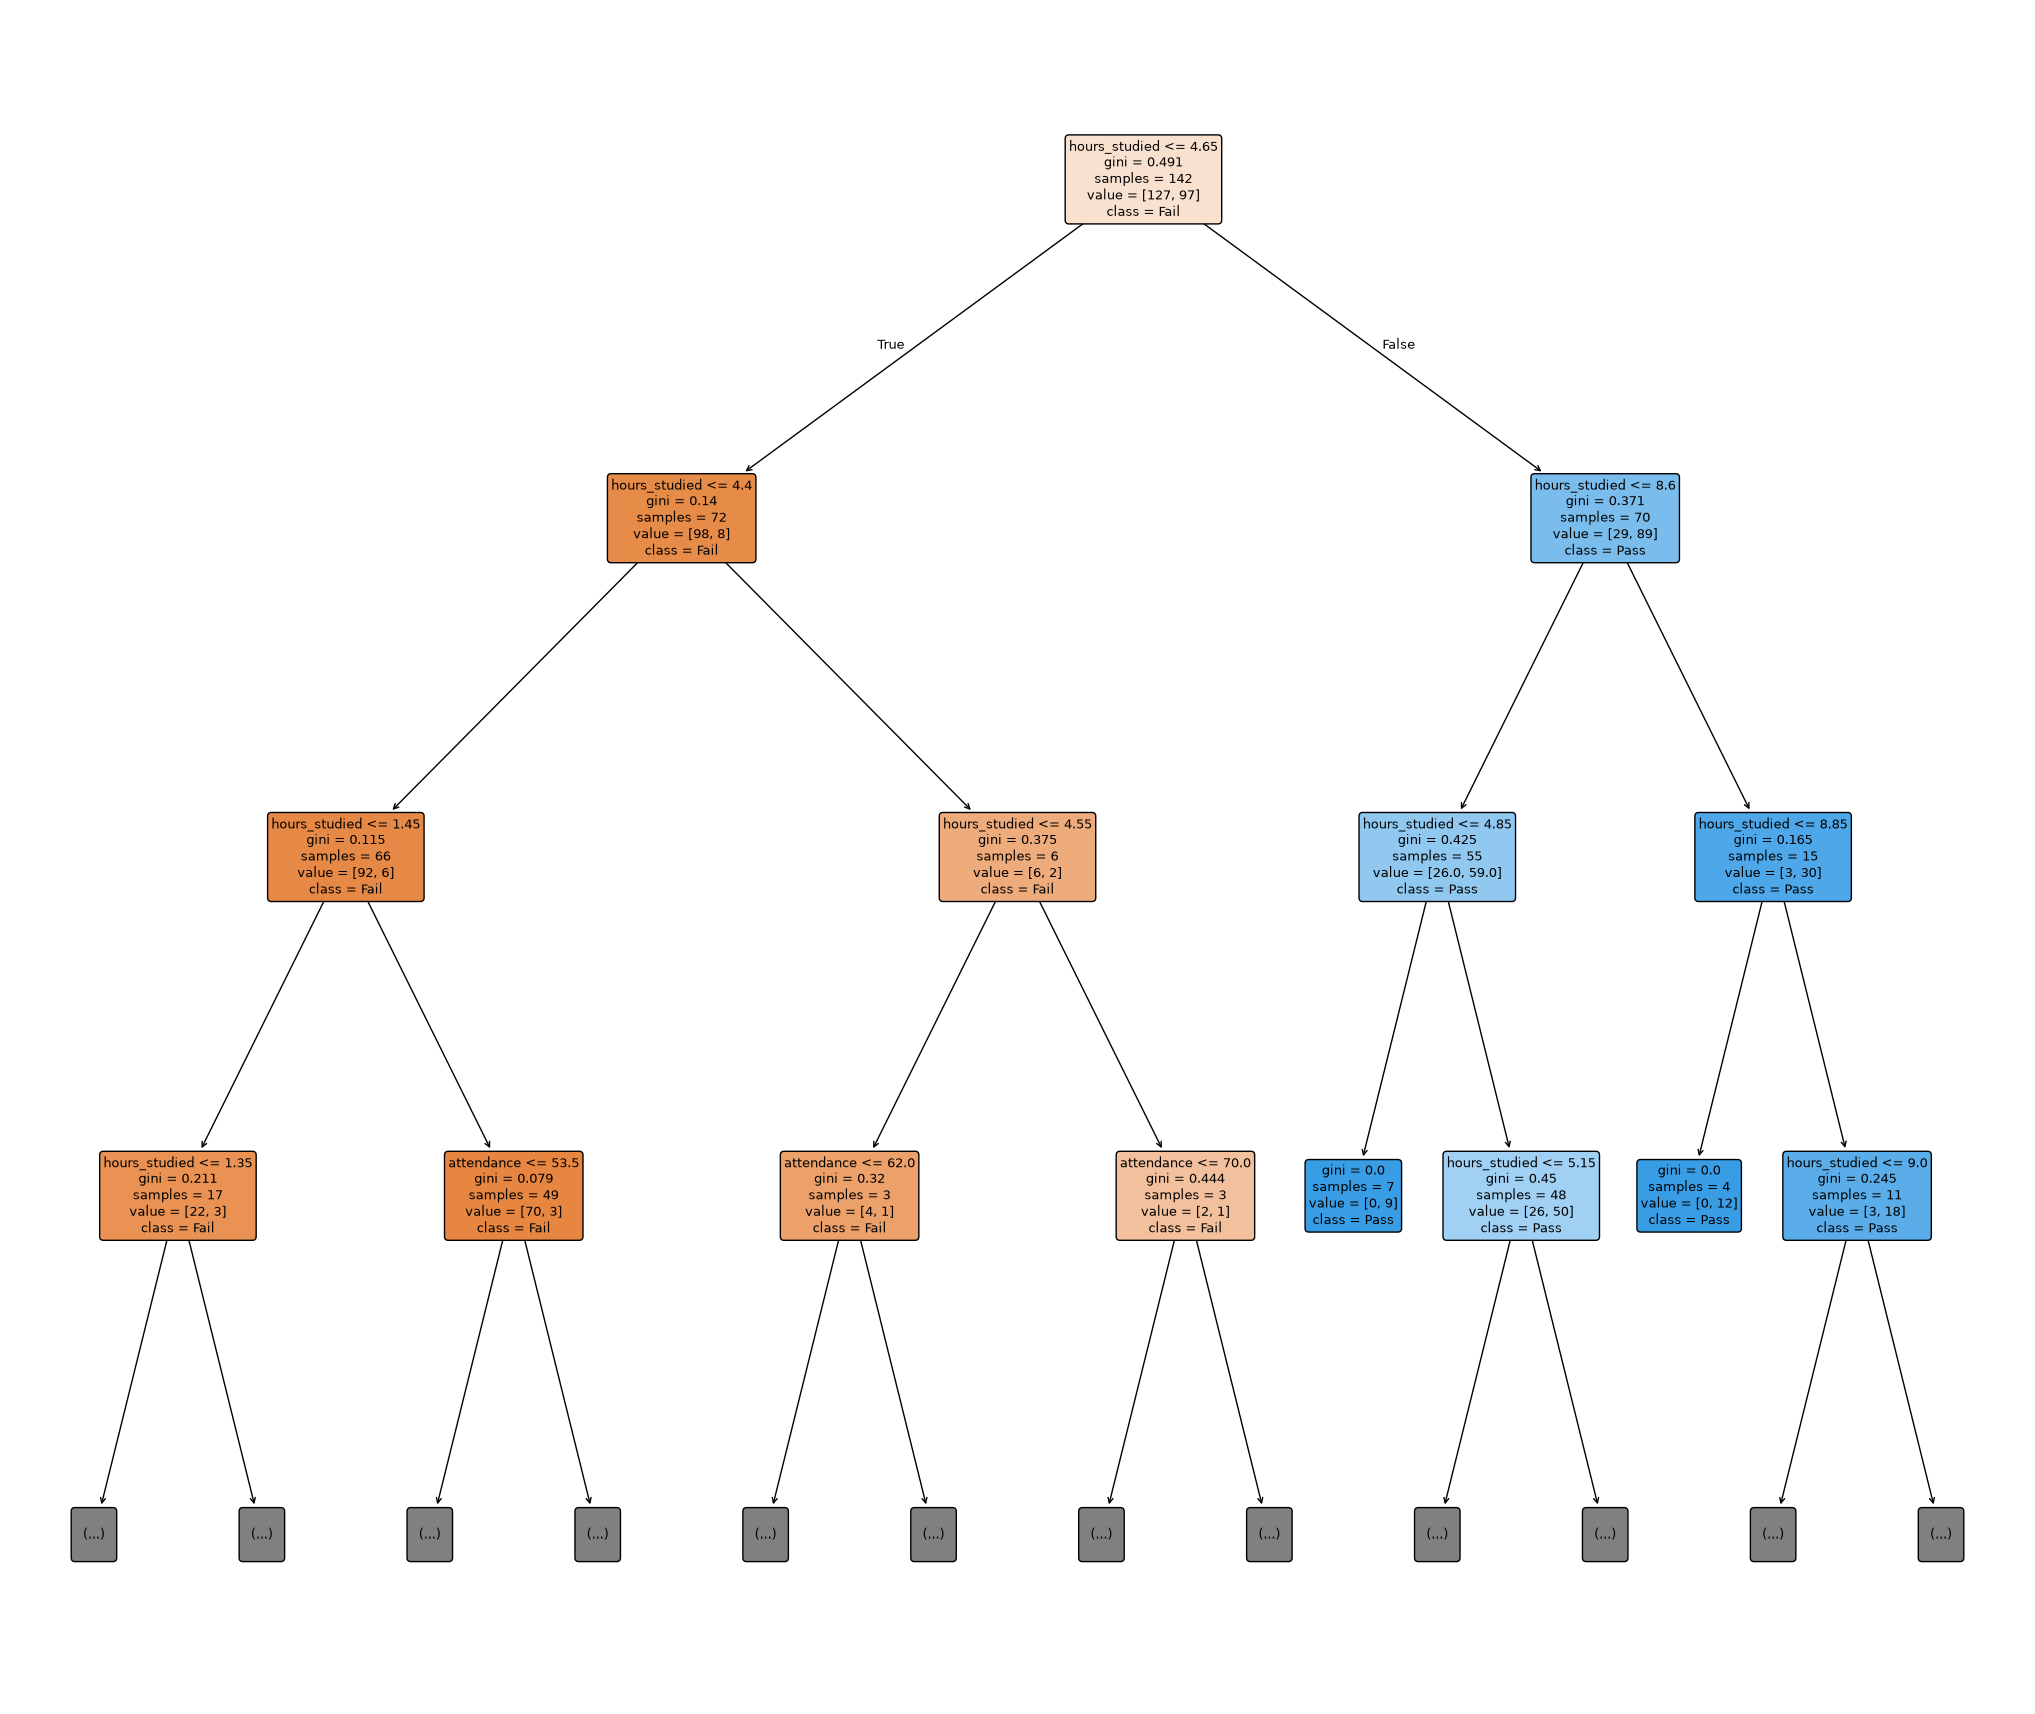

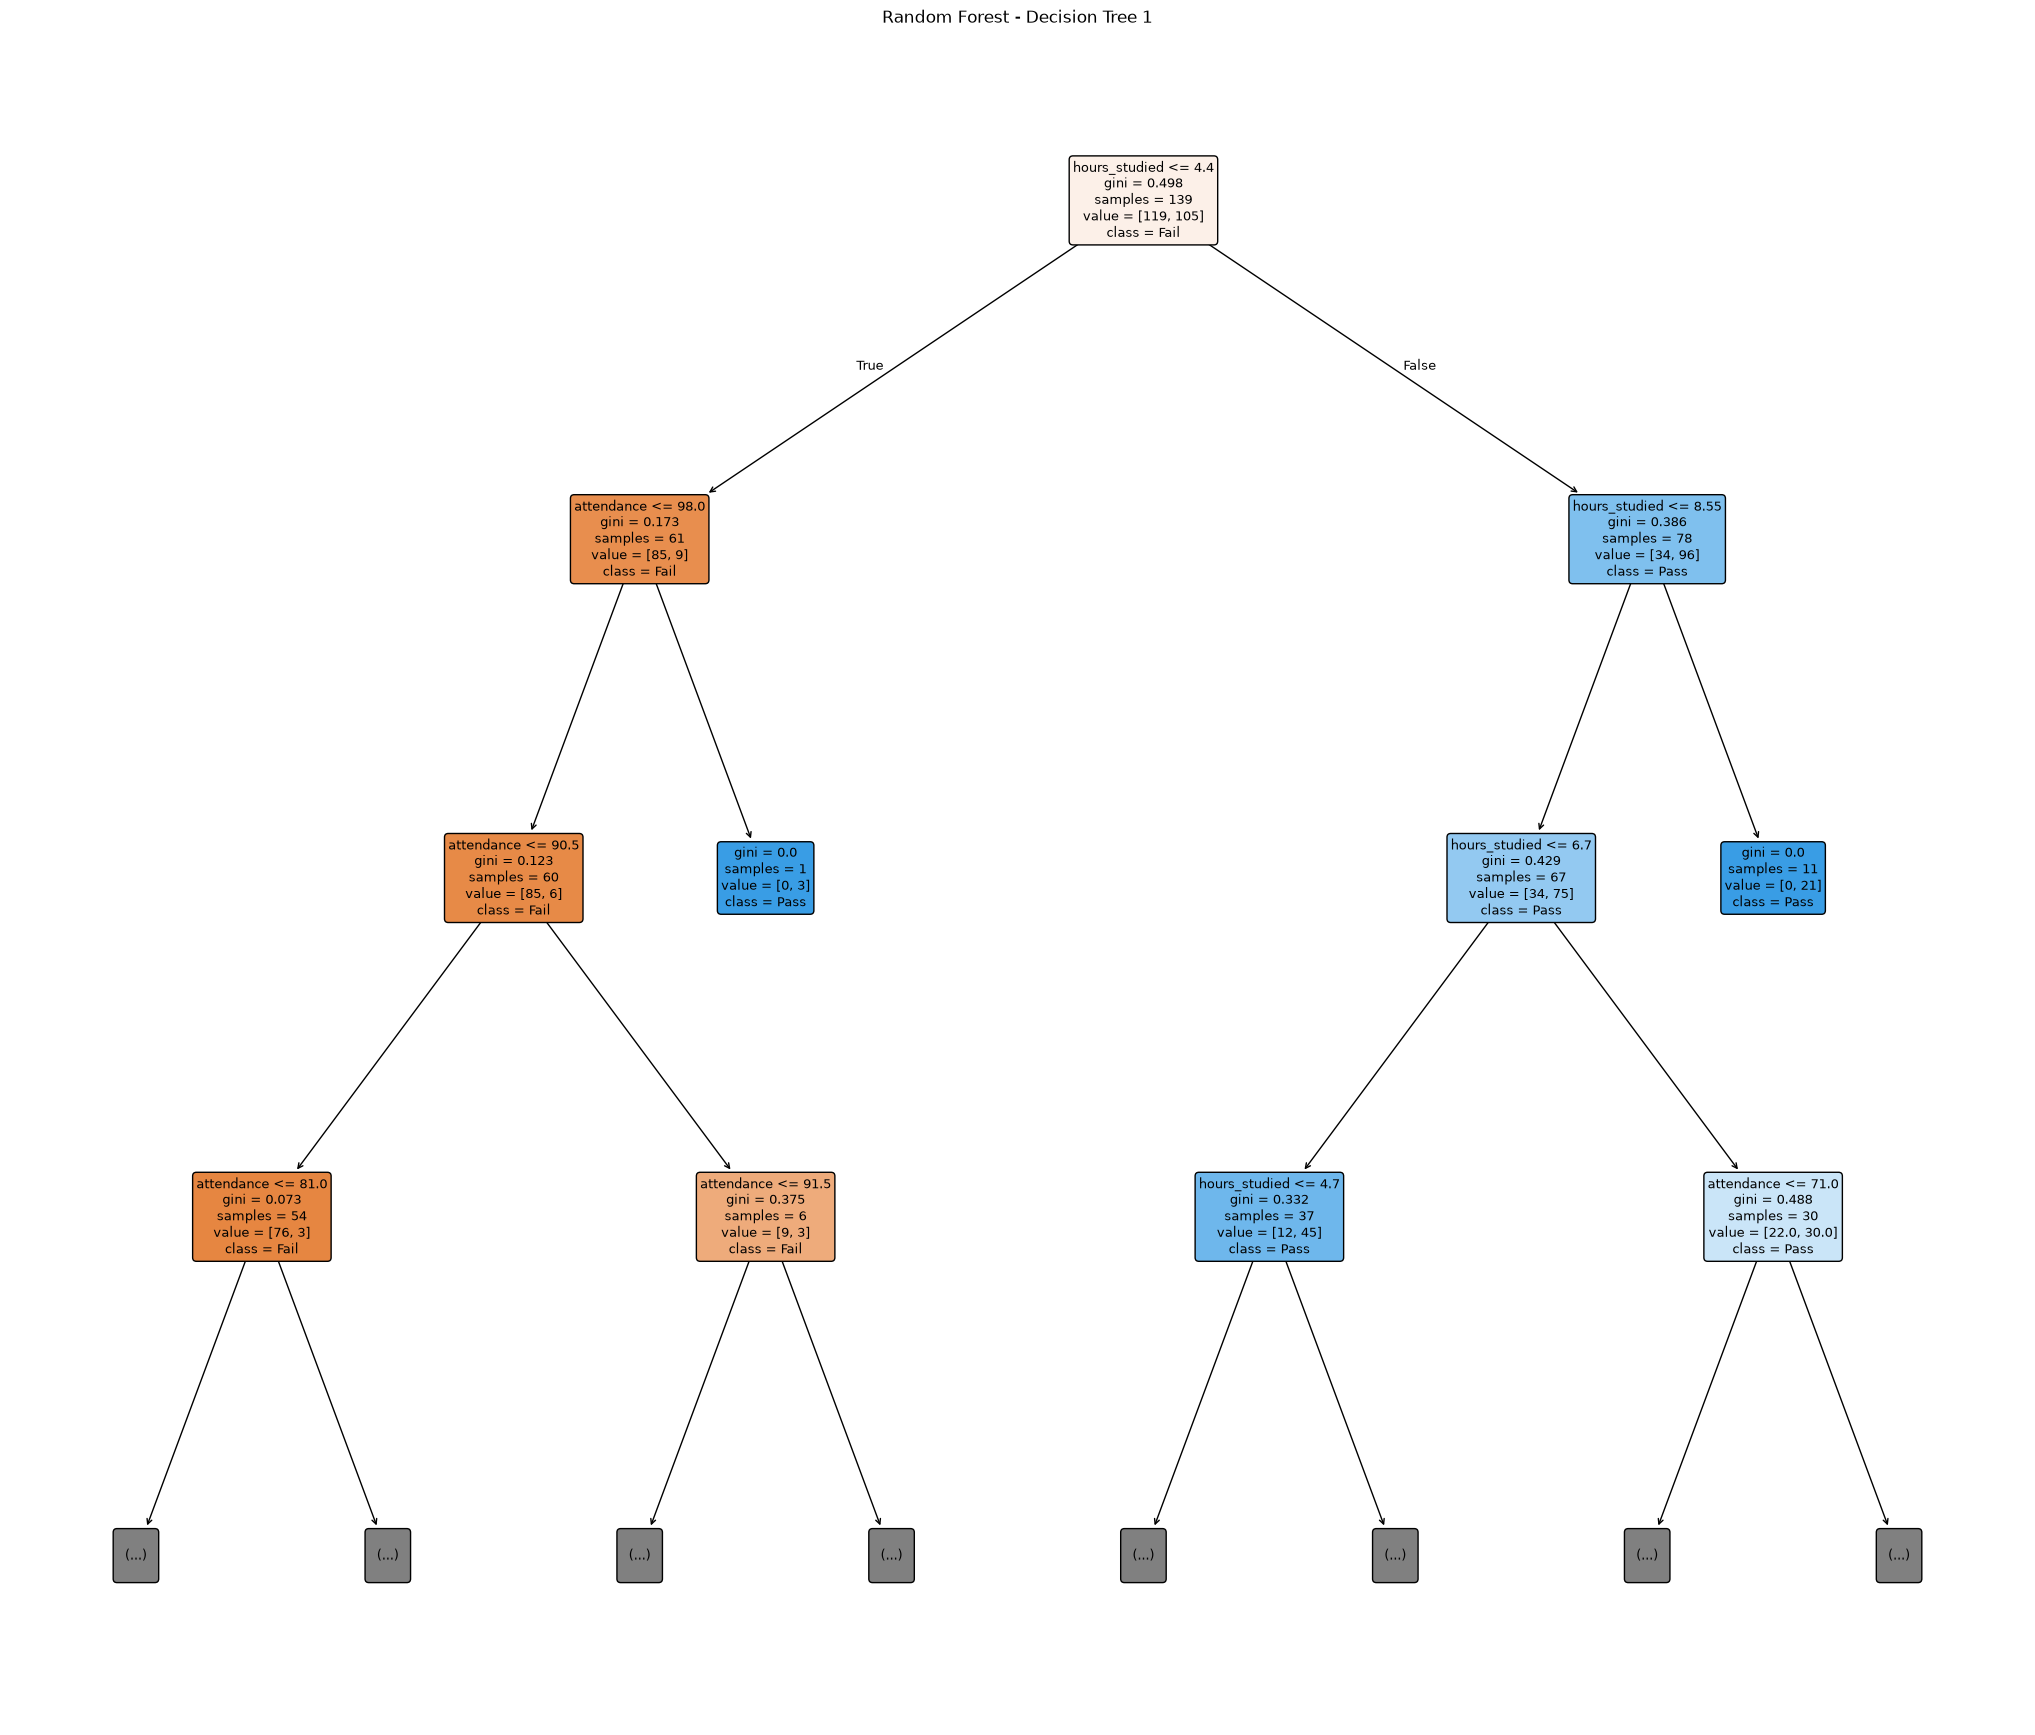

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
for i in range(3):
# Create a large figure to display the tree clearly.
    plt.figure(figsize=(26, 22))

# Plot the first Decision Tree from the Random Forest.
    plot_tree(
        forest.estimators_[i],         # Select the first tree from the forest.
        feature_names=features,        # Display hours_studied and attendance.
        class_names=["Fail", "Pass"],  # Display the class names.
        filled=True,                   # Use colors to distinguish classes.
        rounded=True,                  # Use rounded boxes for tree nodes.
        fontsize=9,                    # Set the text size.
        max_depth=3                    # Display only the first 3 decision levels.
)

# Add a title.
plt.title("Random Forest - Decision Tree 1")

# Display the diagram.
plt.show()

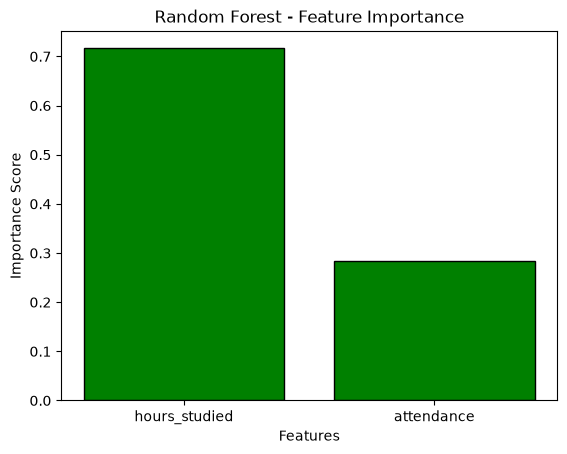

In [ ]:
import matplotlib.pyplot as plt

# Get feature importance scores from the trained forest.
importance = forest.feature_importances_

# Create a bar graph.
plt.bar(features, importance , edgecolor="black", color="green")

# Add graph labels.
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.title("Random Forest - Feature Importance")

# Display the graph.
plt.show()

**Line-by-line code walkthrough**

- `from sklearn.ensemble import RandomForestClassifier` — Import the functions or models needed for this step.
- `forest = RandomForestClassifier(` — Assign the resulting value to this variable for later use.
- `n_estimators=80, max_depth=5,` — Assign the resulting value to this variable for later use.
- `random_state=42)` — Assign the resulting value to this variable for later use.
- `forest.fit(Xt[features], yt)` — Fit the estimator using the provided training examples.
- `print("Accuracy:", round(` — Display the computed value or model result.
- `forest.score(Xv[features], yv), 3))` — Measure performance on the supplied labeled records.

**How to interpret the result:** The printed accuracy is the share of correctly classified test students. It may differ from the tree score; use the same test set for comparison.

**Common mistake:** More trees do not guarantee improved accuracy and require more work. Start with sensible defaults and compare to the baseline.

### Student practice

Which model is easier to explain to a new student: one shallow tree or 100 trees?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

One shallow tree. A forest may predict better but is less transparent than a single path.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 11 — Overfitting, Underfitting and Generalization

**What it means:** Underfitting happens when a model is too simple to learn important patterns. Overfitting happens when it memorizes training details rather than general patterns.

**Why it is useful:** Generalization means doing well on new data. Compare train and validation scores to understand whether a model is learning broadly useful patterns.

**Real situation:** A depth-20 tree gets 100% training accuracy but noticeably worse test accuracy; a depth-1 tree scores poorly on both.

**Important terms:** **Underfitting:** Low train and low test performance; **Overfitting:** High train but lower test performance; **Generalization:** Good performance on unseen rows

**Workflow:** Fit a simple tree → Record train and test scores → Fit a deeper tree → Compare the score gap

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
for depth in [1, 3, 10]:  # Repeat the following indented statements for each value.
    m = DecisionTreeClassifier(
        max_depth=depth, random_state=42)  # Assign the resulting value to this variable for later use.
    m.fit(Xt[features], yt)  # Fit the estimator using the provided training examples.
    print(depth,
       round(m.score(Xt[features], yt), 2),
       round(m.score(Xv[features], yv), 2))

1 0.8 0.73
3 0.83 0.7
10 0.95 0.66


**Line-by-line code walkthrough**

- `for depth in [1, 3, 10]:` — Repeat the following indented statements for each value.
- `m = DecisionTreeClassifier(` — Assign the resulting value to this variable for later use.
- `max_depth=depth, random_state=42)` — Assign the resulting value to this variable for later use.
- `m.fit(Xt[features], yt)` — Fit the estimator using the provided training examples.
- `print(depth,` — Display the computed value or model result.
- `round(m.score(Xt[features], yt), 2),` — Measure performance on the supplied labeled records.
- `round(m.score(Xv[features], yv), 2))` — Measure performance on the supplied labeled records.

**How to interpret the result:** Each line prints depth, training accuracy and test accuracy. A growing gap signals possible overfitting.

**Common mistake:** A good result is not simply the largest training score. Choose a model that stays reliable on unseen data.

### Student practice

A model has 1.00 training accuracy but 0.62 test accuracy. Name the likely problem.

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Likely overfitting: it learned training details that did not transfer to new records.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Compare train/test accuracy as complexity changes.
for depth in [2, 5, 12]:  # Repeat the following indented statements for each value.
    model = DecisionTreeClassifier(max_depth=depth,random_state=42)
    model.fit(Xt, yt)  # Fit the estimator using the provided training examples.
    print(depth, "train",round(model.score(Xt,yt),2),
          "test",round(model.score(Xv,yv),2))

2 train 0.81 test 0.62
5 train 0.86 test 0.7
12 train 0.98 test 0.7


**Line-by-line code walkthrough**

- `for depth in [2, 5, 12]:` — Repeat the following indented statements for each value.
- `model = DecisionTreeClassifier(max_depth=depth,random_state=42)` — Assign the resulting value to this variable for later use.
- `model.fit(Xt, yt)` — Fit the estimator using the provided training examples.
- `print(depth, "train",round(model.score(Xt,yt),2),` — Display the computed value or model result.
- `"test",round(model.score(Xv,yv),2))` — Measure performance on the supplied labeled records.

## Lesson 12 — Cross-Validation and Error Analysis

**What it means:** Cross-validation repeatedly splits training data into folds. Each fold gets a turn as validation while the remaining folds train the model.

**Why it is useful:** Averaging fold scores provides a more stable view than one lucky validation split. Afterwards, use the untouched test set for the final report.

**Real situation:** With five folds, the model trains five times. A different fifth of training data is used for validation on each run.

**Important terms:** **Fold:** One subset used for temporary validation; **CV score:** Average evaluation across held-out folds; **Error analysis:** Investigating cases the model predicts incorrectly

**Workflow:** Hold out test set → Split training into folds → Fit and score each fold → Review errors and averages

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [22]:
from sklearn.model_selection import cross_val_score  # Import the functions or models needed for this step.
model = DecisionTreeClassifier(
    max_depth=3, random_state=42)  # Assign the resulting value to this variable for later use.
scores = cross_val_score(
    model, Xt[features], yt, cv=5)
print(scores.round(2))  # Display the computed value or model result.
print("Average:", scores.mean().round(2))  # Display the computed value or model result.

[0.62 0.82 0.84 0.69 0.77]
Average: 0.75


**Line-by-line code walkthrough**

- `from sklearn.model_selection import cross_val_score` — Import the functions or models needed for this step.
- `model = DecisionTreeClassifier(` — Assign the resulting value to this variable for later use.
- `max_depth=3, random_state=42)` — Assign the resulting value to this variable for later use.
- `scores = cross_val_score(` — Assign the resulting value to this variable for later use.
- `model, Xt[features], yt, cv=5)` — Assign the resulting value to this variable for later use.
- `print(scores.round(2))` — Display the computed value or model result.
- `print("Average:", scores.mean().round(2))` — Display the computed value or model result.

**How to interpret the result:** You will see five validation accuracies and their average. A wide spread means performance changes depending on the training subset.

**Common mistake:** Do not cross-validate after repeatedly tuning on the final test set. Keep that test set reserved.

### Student practice

Why should the final test set remain untouched during model selection?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Otherwise you may indirectly optimize for the test set, making the reported performance too optimistic.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [23]:
# CV happens within the training data.
from sklearn.model_selection import cross_val_score  # Import the functions or models needed for this step.
model = DecisionTreeClassifier(max_depth=4,random_state=42)  # Assign the resulting value to this variable for later use.
fold_scores = cross_val_score(model, Xt, yt, cv=5)  # Assign the resulting value to this variable for later use.
print("Five folds:", fold_scores.round(2))  # Display the computed value or model result.
print("Average:", round(fold_scores.mean(),2))  # Display the computed value or model result.

Five folds: [0.76 0.82 0.84 0.69 0.75]
Average: 0.77


**Line-by-line code walkthrough**

- `from sklearn.model_selection import cross_val_score` — Import the functions or models needed for this step.
- `model = DecisionTreeClassifier(max_depth=4,random_state=42)` — Assign the resulting value to this variable for later use.
- `fold_scores = cross_val_score(model, Xt, yt, cv=5)` — Assign the resulting value to this variable for later use.
- `print("Five folds:", fold_scores.round(2))` — Display the computed value or model result.
- `print("Average:", round(fold_scores.mean(),2))` — Display the computed value or model result.

## Wrap-up

Which part of the workflow would you explain to a beginner? What could go wrong if we leaked target information or judged models on training data?